In [1]:
import io, zipfile, urllib.request
import numpy as np, pandas as pd

def download_month(year, month, symbol="BTCUSDT", interval="1h"):
    """One monthly file of hourly bars from Binance's free data site."""
    name = f"{symbol}-{interval}-{year}-{month:02d}"
    url = f"https://data.binance.vision/data/spot/monthly/klines/{symbol}/{interval}/{name}.zip"
    z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
    return pd.read_csv(z.open(z.namelist()[0]), header=None)

raw = pd.concat([download_month(y, m) for y in range(2020, 2026) for m in range(1, 13)])
raw.columns = ["open_time", "open", "high", "low", "close", "volume", "close_time",
               "quote_volume", "trades", "taker_buy_volume", "taker_buy_quote", "ignore"]

# Binance switched from milliseconds to microseconds in 2025 -> put everything in milliseconds
t = raw["open_time"].astype("int64")
t = np.where(t > 1e14, t // 1000, t)

df = raw[["open", "high", "low", "close", "volume", "quote_volume", "trades", "taker_buy_volume"]].astype(float)
df.index = pd.to_datetime(t, unit="ms")
df = df[~df.index.duplicated()].sort_index()

print(df.shape, df.index.min(), df.index.max())
expected = pd.date_range(df.index.min(), df.index.max(), freq="1h")
print("missing hours:", len(expected.difference(df.index)))
df.tail()

(52577, 8) 2020-01-01 00:00:00 2025-12-31 23:00:00
missing hours: 31


,open,high,low,close,volume,quote_volume,trades,taker_buy_volume
2025-12-31 19:00:00,87684.08,87870.02,87516.70,87541.85,622.18859,5.456200e+07,128037.0,299.31945
2025-12-31 20:00:00,87541.85,87712.13,87250.00,87662.01,770.32743,6.737396e+07,171298.0,356.39420
2025-12-31 21:00:00,87662.01,87879.04,87662.01,87799.97,383.85550,3.369446e+07,65264.0,197.12323
2025-12-31 22:00:00,87799.97,87879.04,87656.19,87728.29,236.18697,2.073407e+07,55353.0,135.86396
2025-12-31 23:00:00,87728.30,87728.30,87619.67,87648.22,191.19123,1.676238e+07,38240.0,86.88848


In [2]:
H = 24          # look 24 hours ahead
DROP = -0.05    # crash = price falls at least 5%

# lowest price over the NEXT 24 hours (t+1 ... t+24)
future_low = df["low"].rolling(H).min().shift(-H)
df["fwd_drawdown"] = future_low / df["close"] - 1
df["crash"] = (df["fwd_drawdown"] <= DROP).astype(float)
df.loc[df["fwd_drawdown"].isna(), "crash"] = np.nan        # last 24 hours: future unknown

starts = (df["crash"] == 1) & (df["crash"].shift(1) != 1)   # first hour of each crash episode
print(f"crash hours: {df['crash'].mean():.1%}")
print(f"crash episodes: {starts.sum()}")
print(df["crash"].groupby(df.index.year).mean().round(3))

crash hours: 10.3%
crash episodes: 624
2020    0.106
2021    0.222
2022    0.125
2023    0.031
2024    0.080
2025    0.056
Name: crash, dtype: float64


In [4]:
H = 72          # look 72 hours ahead
DROP = -0.10    # crash = price falls at least 10%
# lowest price over the NEXT 24 hours (t+1 ... t+24)
future_low = df["low"].rolling(H).min().shift(-H)
df["fwd_drawdown"] = future_low / df["close"] - 1
df["crash"] = (df["fwd_drawdown"] <= DROP).astype(float)
df.loc[df["fwd_drawdown"].isna(), "crash"] = np.nan        # last 24 hours: future unknown

starts = (df["crash"] == 1) & (df["crash"].shift(1) != 1)   # first hour of each crash episode
print(f"crash hours: {df['crash'].mean():.1%}")
print(f"crash episodes: {starts.sum()}")
print(df["crash"].groupby(df.index.year).mean().round(3))

crash hours: 7.3%
crash episodes: 214
2020    0.063
2021    0.173
2022    0.091
2023    0.015
2024    0.047
2025    0.050
Name: crash, dtype: float64


In [7]:
r = np.log(df["close"]).diff()                         # hourly log return
hl2 = np.log(df["high"] / df["low"]) ** 2              # squared high-low range
signed_usd = (2 * df["taker_buy_volume"] - df["volume"]) * df["close"]   # buy $ minus sell $
W, LONG = 24, 168                                      # 24 hours, 7 days

f = pd.DataFrame(index=df.index)
# 1. volatility (Parkinson): uses the high-low range, more precise than close-to-close
f["vol"] = np.sqrt(hl2.rolling(W).mean() / (4 * np.log(2)))
# 2. volatility ratio: today's volatility vs the last week's -> is it accelerating?
f["vol_ratio"] = f["vol"] / np.sqrt(hl2.rolling(LONG).mean() / (4 * np.log(2)))
# 3. Amihud: total price move per dollar traded over 24h -> is the market thin?
f["amihud"] = r.abs().rolling(W).sum() / df["quote_volume"].rolling(W).sum()
# 4. Kyle's lambda: slope of return on signed dollar flow -> how much flow moves the price
f["kyle"] = r.rolling(W).cov(signed_usd) / signed_usd.rolling(W).var()
# 5. trade intensity: trades in the last 24h vs the average day of the last week -> panic?
f["intensity"] = df["trades"].rolling(W).sum() / (df["trades"].rolling(LONG).sum() / 7)
# 6. average trade size in dollars -> whales vs retail
f["trade_size"] = df["quote_volume"].rolling(W).sum() / df["trades"].rolling(W).sum()
# 7. (candidate) signed imbalance: net buying (+) or selling (-) over 24h
f["imbalance"] = signed_usd.rolling(W).sum() / df["quote_volume"].rolling(W).sum()

f["crash"] = df["crash"]
f = f.dropna()
print(f.shape)
f.describe().T.round(6)


(52338, 8)


,count,mean,std,min,25%,50%,75%,max
vol,52338.0,0.006024,0.004013,0.000469,0.003720,0.005205,0.007177,0.078137
vol_ratio,52338.0,0.952749,0.322006,0.181060,0.744820,0.913432,1.119496,2.563997
amihud,52338.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
kyle,52338.0,0.000000,0.000000,-0.000000,0.000000,0.000000,0.000000,0.000000
intensity,52338.0,1.008121,0.309122,0.179525,0.813563,0.982127,1.166776,2.854064
trade_size,52338.0,1070.057221,451.889832,240.375825,702.145789,974.714091,1441.338404,2434.891292
imbalance,52338.0,-0.019399,0.039603,-0.288077,-0.042005,-0.015322,0.003947,0.147005
crash,52338.0,0.073388,0.260775,0.000000,0.000000,0.000000,0.000000,1.000000


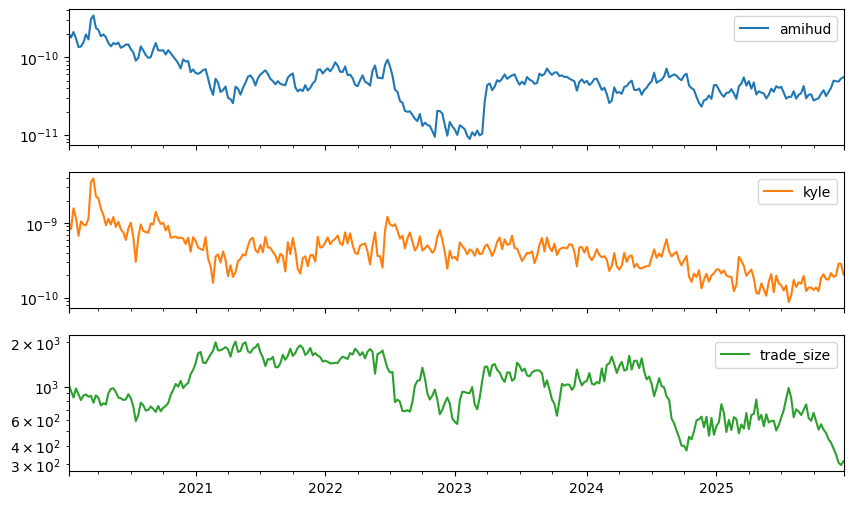

In [8]:
f[["amihud", "kyle", "trade_size"]].resample("W").mean().plot(subplots=True, logy=True, figsize=(10, 6));

In [9]:
(f[["amihud", "kyle"]] * 1e9).describe().T

,count,mean,std,min,25%,50%,75%,max
amihud,52338.0,0.059083,0.047720,0.004992,0.033715,0.046567,0.065177,0.560833
kyle,52338.0,0.488878,0.483921,-0.994787,0.225268,0.386212,0.600902,8.504163


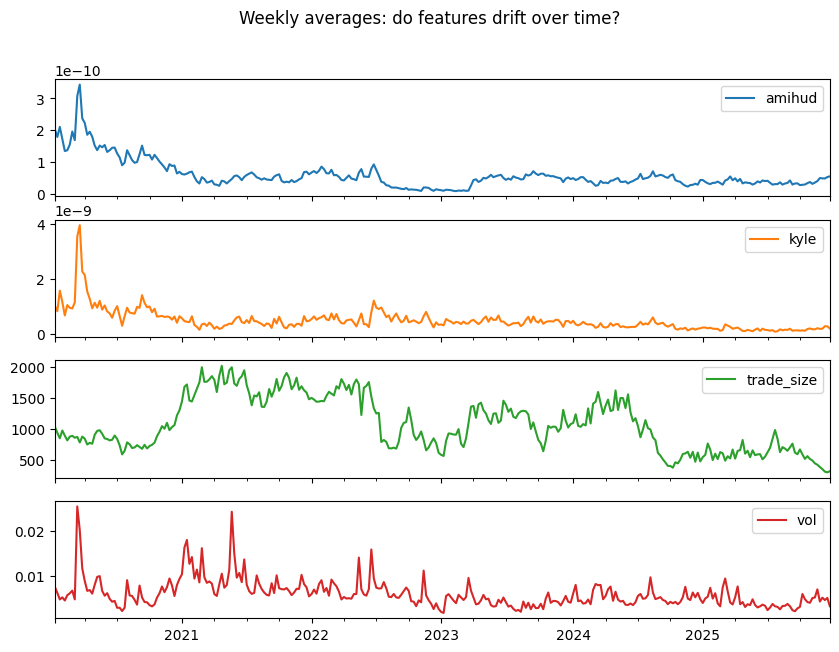

In [10]:
f[["amihud", "kyle", "trade_size", "vol"]].resample("W").mean().plot(
    subplots=True, figsize=(10, 7), title="Weekly averages: do features drift over time?");

In [11]:
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

# relative versions: how unusual is the value compared with the past 30 days (720 hours)
for c in ["amihud", "kyle", "trade_size"]:
    x = f[c]
    f[c + "_rel"] = (x - x.rolling(720).mean()) / x.rolling(720).std()

train = f.loc["2020":"2022"].dropna()
y = train["crash"]
print(train.shape, "crash rate:", round(y.mean(), 3))

(25388, 11) crash rate: 0.113


In [13]:
rows = []
b = y.mean()                                      # crash rate (~9%)
for c in train.columns.drop(["crash", "stress"], errors="ignore"):
    x = train[c]
    auc = roc_auc_score(y, x)
    sign = 1 if auc >= 0.5 else -1                # does a high or a low value warn of a crash?
    s = sign * x                                  # flip so that higher = more dangerous
    pr_auc = average_precision_score(y, s)
    flag = s >= s.quantile(1 - b)                 # "yes" for the top b% of hours
    f1 = (flag & (y == 1)).sum() / flag.sum()     # F1 (= precision = recall here)
    rows.append([c, sign, round(max(auc, 1 - auc), 3), round(pr_auc, 3), round(f1, 3)])

res = pd.DataFrame(rows, columns=["feature", "direction", "AUC", "PR_AUC", "F1"]).set_index("feature")
print("useless feature scores: AUC 0.5, PR_AUC and F1 ≈", round(b, 3))
res.sort_values("PR_AUC", ascending=False)

useless feature scores: AUC 0.5, PR_AUC and F1 ≈ 0.113


,direction,AUC,PR_AUC,F1
feature,,,,
vol,1,0.667,0.231,0.254
trade_size,1,0.686,0.226,0.266
trade_size_rel,1,0.616,0.152,0.169
vol_ratio,1,0.546,0.147,0.149
kyle_rel,1,0.519,0.146,0.164
imbalance,-1,0.562,0.138,0.145
intensity,1,0.542,0.136,0.156
kyle,-1,0.560,0.134,0.161
amihud_rel,1,0.523,0.131,0.159


In [14]:
for yr in ["2020", "2021", "2022"]:
    d = train.loc[yr]
    print(yr, round(roc_auc_score(d["crash"], d["trade_size"]), 3),
              round(roc_auc_score(d["crash"], d["trade_size_rel"]), 3))

2020 0.59 0.53
2021 0.652 0.631
2022 0.685 0.658


In [15]:
cands = ["vol", "trade_size", "kyle", "vol_ratio", "imbalance", "intensity", "amihud_rel"]
corr = train[cands].corr(method="spearman").round(2)
corr

,vol,trade_size,kyle,vol_ratio,imbalance,intensity,amihud_rel
vol,1.00,0.52,0.06,0.48,-0.07,0.37,0.21
trade_size,0.52,1.00,-0.43,0.24,0.02,0.14,0.03
kyle,0.06,-0.43,1.00,0.05,-0.08,-0.01,0.31
vol_ratio,0.48,0.24,0.05,1.00,-0.07,0.83,-0.02
imbalance,-0.07,0.02,-0.08,-0.07,1.00,0.00,-0.12
intensity,0.37,0.14,-0.01,0.83,0.00,1.00,-0.25
amihud_rel,0.21,0.03,0.31,-0.02,-0.12,-0.25,1.00


DROP INTENSITY

In [16]:
rng = np.random.default_rng(0)

def f1_top(x, y):                                  # same F1 as before
    sign = 1 if roc_auc_score(y, x) >= 0.5 else -1
    s = sign * x
    flag = s >= s.quantile(1 - y.mean())
    return (flag & (y == 1)).sum() / flag.sum()

keep = ["vol", "trade_size", "kyle", "vol_ratio", "imbalance", "amihud_rel"]
ys = train["crash"].reset_index(drop=True)
out = []
for c in keep:
    x = train[c].reset_index(drop=True)
    real = f1_top(x, ys)
    fake = [f1_top(pd.Series(np.roll(x.values, rng.integers(720, len(x) - 720))), ys) for _ in range(200)]
    out.append([c, round(real, 3), round(np.percentile(fake, 95), 3), round(np.mean(np.array(fake) >= real), 3)])

pd.DataFrame(out, columns=["feature", "real_F1", "luck_95%", "p_value"]).set_index("feature")

,real_F1,luck_95%,p_value
feature,,,
vol,0.254,0.183,0.000
trade_size,0.266,0.200,0.005
kyle,0.161,0.199,0.185
vol_ratio,0.149,0.170,0.165
imbalance,0.145,0.164,0.240
amihud_rel,0.159,0.172,0.115


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X = train[["vol", "trade_size", "kyle", "vol_ratio", "imbalance", "amihud_rel"]].copy()
for c in ["vol", "trade_size", "vol_ratio"]:
    X[c] = np.log(X[c])                     # tame the spikes (all positive)
y = train["crash"]
fit, val = X.loc["2020":"2021"].index, X.loc["2022"].index

def val_score(cols):
    m = make_pipeline(StandardScaler(), LogisticRegression())
    m.fit(X.loc[fit, cols], y.loc[fit])                 # learn on 2020-21
    p = m.predict_proba(X.loc[val, cols])[:, 1]         # predict 2022
    return round(average_precision_score(y.loc[val], p), 3)

base = ["vol", "trade_size"]
print("useless:", round(y.loc[val].mean(), 3), "| base:", val_score(base))
for c in ["kyle", "vol_ratio", "imbalance", "amihud_rel"]:
    print("+", c, val_score(base + [c]))
print("all 6:", val_score(base + ["kyle", "vol_ratio", "imbalance", "amihud_rel"]))

useless: 0.091 | base: 0.218
+ kyle 0.221
+ vol_ratio 0.178
+ imbalance 0.249
+ amihud_rel 0.217
all 6: 0.255


In [20]:
!pip install -q hmmlearn
from hmmlearn.hmm import GaussianHMM

Z = f[["vol", "trade_size", "imbalance"]].copy()
Z["vol"] = np.log(Z["vol"])
Z["trade_size"] = np.log(Z["trade_size"])
mu = Z.loc["2020":"2021"].mean()
sd = Z.loc["2020":"2021"].std()
Z = (Z - mu) / sd

In [21]:
from scipy.stats import multivariate_normal

def filtered_probs(m, X):
    X = np.asarray(X)
    K = m.n_components
    logB = np.column_stack([multivariate_normal(m.means_[k], m.covars_[k]).logpdf(X) for k in range(K)])
    B = np.exp(logB - logB.max(axis=1, keepdims=True))
    alpha = np.zeros((len(X), K))
    a = m.startprob_ * B[0]
    alpha[0] = a / a.sum()
    for t in range(1, len(X)):
        a = (alpha[t - 1] @ m.transmat_) * B[t]
        alpha[t] = a / a.sum()
    return alpha

crash = f["crash"].reindex(Z.index)
Zfit, Zval = Z.loc["2020":"2021"], Z.loc["2022"]
yfit, yval = crash.loc["2020":"2021"], crash.loc["2022"]
starts = (yval == 1) & (yval.shift(1) != 1)

rows = []
for k in [2, 3, 4, 5]:
    best = None
    for seed in range(5):
        m = GaussianHMM(n_components=k, covariance_type="full", n_iter=200, random_state=seed).fit(Zfit)
        if best is None or m.score(Zfit) > best.score(Zfit):
            best = m
    pf = filtered_probs(best, Zfit)
    pv = filtered_probs(best, Zval)
    rate = (pf * yfit.values[:, None]).sum(0) / pf.sum(0)
    score_fit = pf @ rate
    score_val = pv @ rate
    thr = np.quantile(score_fit, 0.80)
    alarm = pd.Series(score_val >= thr, index=Zval.index)
    rows.append([k, rate.round(3), round(alarm.mean(), 2), int(alarm[starts].sum()), int(starts.sum())])

pd.DataFrame(rows, columns=["K", "crash_rate_per_regime", "alarm_time_2022", "crashes_caught", "crashes_2022"])

,K,crash_rate_per_regime,alarm_time_2022,crashes_caught,crashes_2022
0,2,"[0.171, 0.066]",0.16,7,45
1,3,"[0.051, 0.172, 0.084]",0.19,7,45
2,4,"[0.142, 0.021, 0.225, 0.081]",0.16,11,45
3,5,"[0.032, 0.076, 0.144, 0.095, 0.224]",0.15,14,45


In [22]:
rows = []
for k in range(2, 10):
    best = None
    for seed in range(5):
        m = GaussianHMM(n_components=k, covariance_type="full", n_iter=200, random_state=seed).fit(Zfit)
        if best is None or m.score(Zfit) > best.score(Zfit):
            best = m
    pf = filtered_probs(best, Zfit)
    pv = filtered_probs(best, Zval)
    rate = (pf * yfit.values[:, None]).sum(0) / pf.sum(0)
    thr = np.quantile(pf @ rate, 0.80)
    alarm = pd.Series(pv @ rate >= thr, index=Zval.index)
    rows.append([f"HMM K={k}", round(alarm.mean(), 2), int(alarm[starts].sum())])

va = Zval["vol"] >= Zfit["vol"].quantile(0.80)
rows.append(["vol alone", round(va.mean(), 2), int(va[starts].sum())])

res = pd.DataFrame(rows, columns=["model", "alarm_time_2022", "crashes_caught"])
res["random_would_catch"] = (res["alarm_time_2022"] * starts.sum()).round(1)
res["out_of"] = int(starts.sum())
res

,model,alarm_time_2022,crashes_caught,random_would_catch,out_of
0,HMM K=2,0.16,7,7.2,45
1,HMM K=3,0.19,7,8.6,45
2,HMM K=4,0.16,11,7.2,45
3,HMM K=5,0.15,14,6.8,45
4,HMM K=6,0.19,8,8.6,45
5,HMM K=7,0.14,10,6.3,45
6,HMM K=8,0.09,15,4.0,45
7,HMM K=9,0.16,9,7.2,45
8,vol alone,0.10,11,4.5,45


In [24]:
def run(k, seeds):
    best = None
    for seed in seeds:
        m = GaussianHMM(n_components=k, covariance_type="full", n_iter=200, random_state=seed).fit(Zfit)
        if best is None or m.score(Zfit) > best.score(Zfit):
            best = m
    pf = filtered_probs(best, Zfit)
    pv = filtered_probs(best, Zval)
    rate = (pf * yfit.values[:, None]).sum(0) / pf.sum(0)
    thr = np.quantile(pf @ rate, 0.80)
    alarm = pv @ rate >= thr
    return round(alarm.mean(), 2), int(alarm[starts.values].sum())

rows = []
for k in [5, 8]:
    for g in range(5):
        t, c = run(k, range(5 * g, 5 * g + 5))
        rows.append([k, f"{5*g}-{5*g+4}", t, c, round(t * starts.sum(), 1)])

pd.DataFrame(rows, columns=["K", "seeds", "alarm_time", "caught", "random"])

,K,seeds,alarm_time,caught,random
0,5,0-4,0.15,14,6.8
1,5,5-9,0.11,10,5.0
2,5,10-14,0.24,22,10.8
3,5,15-19,0.22,22,9.9
4,5,20-24,0.15,10,6.8
5,8,0-4,0.09,15,4.0
6,8,5-9,0.17,13,7.6
7,8,10-14,0.10,11,4.5
8,8,15-19,0.09,15,4.0
9,8,20-24,0.10,14,4.5


In [25]:
best, best_ll, best_seed = None, -np.inf, None
for seed in range(25):
    m = GaussianHMM(n_components=8, covariance_type="full", n_iter=200, random_state=seed).fit(Zfit)
    ll = m.score(Zfit)
    if ll > best_ll:
        best, best_ll, best_seed = m, ll, seed
hmm8 = best

pf = filtered_probs(hmm8, Zfit)
pv = filtered_probs(hmm8, Zval)
rate_hmm = (pf * yfit.values[:, None]).sum(0) / pf.sum(0)
thr_hmm = np.quantile(pf @ rate_hmm, 0.80)
alarm_hmm = pv @ rate_hmm >= thr_hmm

print("best seed:", best_seed)
print("crash rate per regime:", rate_hmm.round(3))
print("alarm time 2022:", round(alarm_hmm.mean(), 2),
      "| caught:", int(alarm_hmm[starts.values].sum()), "/", int(starts.sum()),
      "| random:", round(alarm_hmm.mean() * starts.sum(), 1))

best seed: 16
crash rate per regime: [0.257 0.071 0.105 0.114 0.078 0.209 0.077 0.034]
alarm time 2022: 0.09 | caught: 15 / 45 | random: 4.2


In [27]:
from sklearn.mixture import GaussianMixture

rows = []
for k in range(2, 10):
    g = GaussianMixture(n_components=k, covariance_type="full", n_init=25, random_state=0).fit(Zfit)
    gf = g.predict_proba(Zfit)
    gv = g.predict_proba(Zval)
    rate = (gf * yfit.values[:, None]).sum(0) / gf.sum(0)
    thr = np.quantile(gf @ rate, 0.80)
    alarm = gv @ rate >= thr
    rows.append([f"GMM K={k}", round(alarm.mean(), 2), int(alarm[starts.values].sum()),
                 round(alarm.mean() * starts.sum(), 1)])

gmm_res = pd.DataFrame(rows, columns=["model", "alarm_time_2022", "crashes_caught", "random_would_catch"])
gmm_res["x_random"] = (gmm_res["crashes_caught"] / gmm_res["random_would_catch"]).round(2)
gmm_res

,model,alarm_time_2022,crashes_caught,random_would_catch,x_random
0,GMM K=2,0.16,7,7.3,0.96
1,GMM K=3,0.14,12,6.3,1.90
2,GMM K=4,0.12,11,5.3,2.08
3,GMM K=5,0.11,12,5.0,2.40
4,GMM K=6,0.11,15,4.9,3.06
5,GMM K=7,0.11,16,5.2,3.08
6,GMM K=8,0.13,10,5.9,1.69
7,GMM K=9,0.10,10,4.3,2.33


In [31]:
Z2 = f[["vol", "trade_size", "imbalance"]].copy()
Z2["vol"] = np.log(Z2["vol"])
Z2["trade_size"] = np.log(Z2["trade_size"])
mu2, sd2 = Z2.loc["2020":"2022"].mean(), Z2.loc["2020":"2022"].std()
Z2 = (Z2 - mu2) / sd2
y2 = f["crash"].reindex(Z2.index)
tr = Z2.index < "2023-01-01"
te = ~tr
starts2 = (y2 == 1) & (y2.shift(1) != 1)

def report(name, score, thr):
    alarm = pd.Series(score >= thr, index=Z2.index)
    out = []
    for yr in ["2023", "2024", "2025", "2023-2025"]:
        idx = te if yr == "2023-2025" else (Z2.index.year == int(yr))
        a, s = alarm[idx], starts2[idx]
        n, c, rnd = int(s.sum()), int(a[s].sum()), a.mean() * s.sum()
        out.append([name, yr, round(a.mean(), 2), c, n, round(rnd, 1), round(c / rnd, 2)])
    return out

best, best_ll = None, -np.inf
for seed in range(25):
    m = GaussianHMM(n_components=8, covariance_type="full", n_iter=200, random_state=seed).fit(Z2[tr])
    ll = m.score(Z2[tr])
    if ll > best_ll:
        best, best_ll = m, ll
p = filtered_probs(best, Z2)
rate = (p[tr] * y2[tr].values[:, None]).sum(0) / p[tr].sum(0)
s_hmm = p @ rate
rows = report("HMM K=8", s_hmm, np.quantile(s_hmm[tr], 0.80))

g = GaussianMixture(n_components=7, covariance_type="full", n_init=25, random_state=0).fit(Z2[tr])
q = g.predict_proba(Z2)
rate_g = (q[tr] * y2[tr].values[:, None]).sum(0) / q[tr].sum(0)
s_gmm = q @ rate_g
rows += report("GMM K=7", s_gmm, np.quantile(s_gmm[tr], 0.80))

s_vol = Z2["vol"].values
rows += report("vol alone", s_vol, np.quantile(s_vol[tr], 0.80))

final = pd.DataFrame(rows, columns=["model", "period", "alarm_time", "caught", "crashes", "random", "x_random"])
final

,model,period,alarm_time,caught,crashes,random,x_random
0,HMM K=8,2023,0.02,0,6,0.1,0.00
1,HMM K=8,2024,0.15,11,41,6.3,1.74
2,HMM K=8,2025,0.22,8,21,4.6,1.75
3,HMM K=8,2023-2025,0.13,19,68,8.9,2.14
4,GMM K=7,2023,0.04,1,6,0.2,4.55
5,GMM K=7,2024,0.04,6,41,1.6,3.66
6,GMM K=7,2025,0.00,0,21,0.0,0.00
7,GMM K=7,2023-2025,0.03,7,68,1.8,3.92
8,vol alone,2023,0.03,0,6,0.2,0.00
9,vol alone,2024,0.06,9,41,2.6,3.44


In [32]:
for name, s in [("HMM", s_hmm), ("GMM", s_gmm), ("vol", s_vol)]:
    thr = np.quantile(s[te], 0.87)
    alarm = pd.Series(s >= thr, index=Z2.index)[te]
    print(name, "| alarm:", round(alarm.mean(), 2), "| caught:", int(alarm[starts2[te]].sum()), "/ 68")

HMM | alarm: 0.13 | caught: 19 / 68
GMM | alarm: 0.13 | caught: 20 / 68
vol | alarm: 0.13 | caught: 28 / 68
